# BARC-SS example: HUC8 11110203, trapezoidal channel a = 0.4

OWP HAND-FIM rating curves miss the river channel below the water surface because the DEM does not capture it. This notebook adds that channel to the hydrotables with `barc_ss.py`, then runs HAND-FIM with [FIMserv](https://github.com/sdmlua/FIMserv):

- **BARC**: adds the bankfull channel area and wetted perimeter to the hydrotable and recomputes discharge with Manning's equation.
- **BARC-SS**: BARC, plus shifts each rating curve's stage up by the reach's mean-flow depth and anchors it at zero flow.

Example: **HUC8 11110203** (Arkansas River), **trapezoidal channel with a = 0.4**, flood of **3 January 2016, 00:00** (NWM retrospective discharge).

FIMserv writes `code/`, `data/`, and `output/` folders next to this notebook.

### STEP 1. Install and import

Install once:
```bash
pip install fimserve "git+https://github.com/Reizrb/HydroGeom" contextily
```

In [1]:
import sys
sys.path.append("..")          # barc_ss.py is in the repository's main folder

import fimserve as fm
import matplotlib.pyplot as plt
import pandas as pd
import barc_ss

### STEP 2. Settings

- `method`: `"BARC"` or `"BARC-SS"`
- `shape` and `value`: channel shape used to compute bankfull area and wetted perimeter
  - `"a"`: trapezoid, `value` = bottom width / top width (0 = triangle, 1 = rectangle)
  - `"r"`: Dingman's r, `value` = r (1 = triangle, 2 = parabola, larger = rectangle)
  - `"z"`: side slope, `value` = z (z:1)
- `hydroid`: reach whose rating curve is plotted
- `basemap`: map background from `barc_ss.BASEMAPS`: A satellite, B topographic, C light gray, D OpenStreetMap, E USGS imagery + topo, F shaded relief
- `flood_alpha`: transparency of the flooded area

In [2]:
huc = "11110203"
method = "BARC-SS"
shape, value = "a", 0.4

start_date = "2015-12-26"
end_date = "2016-01-05"
value_times = ["2016-01-03 00:00:00"]

hydroid = 23650086
basemap = barc_ss.BASEMAPS["A"]     # satellite
flood_alpha = 0.35                  # transparency of the flooded area (0 = invisible, 1 = solid)

flood_dir = f"output/flood_{huc}"

### STEP 3. Download OWP HAND-FIM (version 4.5) with FIMserv

In [3]:
with barc_ss.quiet():
    fm.DownloadHUC8(huc, version="4.5")

### STEP 4. Channel geometry and BARC-SS

Gets bankfull width and depth and mean-flow depth from [HydroGeom](https://github.com/Reizrb/HydroGeom) for every reach in the HUC8, computes bankfull area and wetted perimeter for the chosen shape, and adjusts the hydrotables. The originals are saved in `output/flood_11110203/original_hydrotables/` the first time, and every run starts from them.

In [4]:
ids = barc_ss.feature_ids(flood_dir, huc)
geometry = barc_ss.channel_geometry(ids, shape=shape, value=value)
hydrotable = barc_ss.apply_barc(flood_dir, huc, geometry, method=method)

BARC-SS applied to 47 branches of HUC8 11110203.


### STEP 5. NWM discharge and HAND-FIM

In [5]:
with barc_ss.quiet():
    fm.getNWMretrospectivedata(huc, start_date, end_date, value_times=value_times)
    fm.runOWPHANDFIM(huc)

### STEP 6. Rating curve of one reach, with the NWM flood discharge

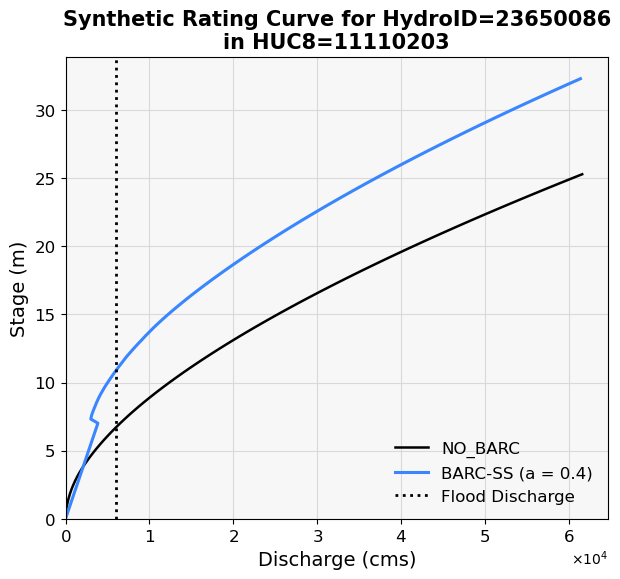

In [6]:
t = pd.to_datetime(value_times[0]).strftime("%Y%m%d%H%M%S")
barc_ss.plot_rating_curve(flood_dir, huc, hydroid, label=f"{method} ({shape} = {value})",
                          discharge_csv=f"data/inputs/NWM_{t}_{huc}.csv")
plt.show()

### STEP 7. Flood map

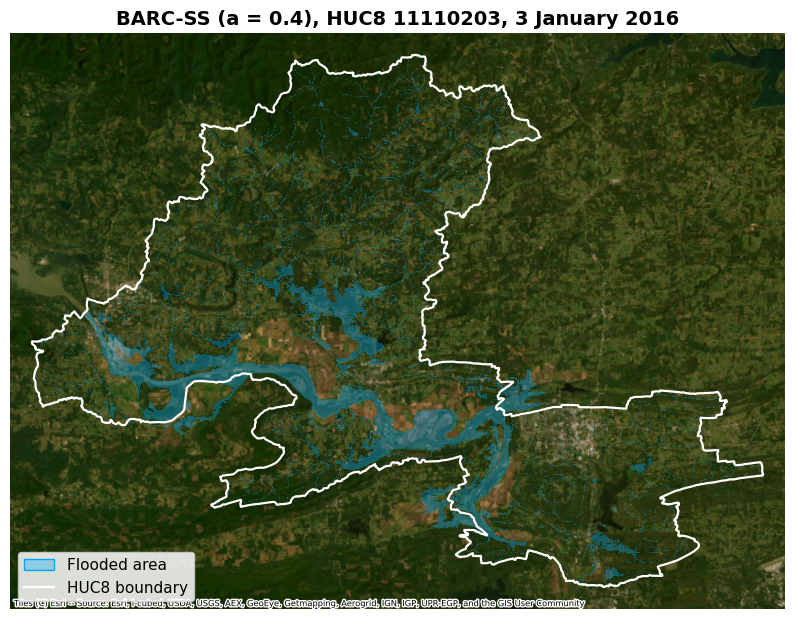

In [7]:
import glob, os

fim = max(glob.glob(f"{flood_dir}/{huc}_inundation/*inundation.tif"), key=os.path.getmtime)
barc_ss.plot_flood_map(fim, f"{flood_dir}/{huc}/wbd.gpkg", huc=huc, basemap=basemap, alpha=flood_alpha,
                       title=f"{method} ({shape} = {value}), HUC8 {huc}, 3 January 2016")
plt.savefig(f"FIM_{huc}_{method}_{shape}{value}.png", dpi=200, bbox_inches="tight")
plt.show()

### Run again with another method or shape

FIMserv skips HAND-FIM if a flood map for the same discharge already exists, so rename the current map first:

```python
os.rename(fim, fim.replace("_inundation.tif", f"_{method}_{shape}{value}_inundation.tif"))
```

Then change the settings in STEP 2 and run STEPS 4 to 7 again (no new download needed). To map the original HAND-FIM, run `barc_ss.restore_hydrotables(flood_dir)` instead of STEP 4.